# Análisis exploratorio de datos : Dengue

## Objetivo

Explorar el dataset consolidado de dengue mediante visualizaciones estadísticas para comprender la distribución de los datos, identificar posibles valores atípicos, analizar relaciones entre variables y reconocer patrones relevantes para la comprensión del comportamiento de la enfermedad.

Se utilizarán histogramas, boxplots, matrices de correlación y gráficos adicionales con Matplotlib y Seaborn.

El análisis buscará traducir los resultados estadísticos en hallazgos útiles para la interpretación epidemiológica y la toma de decisiones.

##  1. Carga de datos y bibliotecas

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_parquet("../datos/procesados/dengue_consolidado.parquet")

print("Dimensiones del dataset:")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

print("\nTipo de dato de cada columna:")
display(df.dtypes.to_frame(name="Tipo de dato"))

Dimensiones del dataset:
Filas: 581071
Columnas: 20

Tipo de dato de cada columna:


,Tipo de dato
SEMANA,int64
ANO,int64
EDAD,int64
UNI_MED,int64
SEXO,str
COD_DPTO_O,int64
COD_MUN_O,int64
AREA,int64
TIP_SS,str
PER_ETN,int64


## 2. Reconocimiento de los datos GRAFICOS 

A continuación, se presentan los gráficos generados a partir del dataset consolidado de dengue, con el objetivo de explorar la distribución de las variables y detectar posibles valores atípicos.

### 1. Histogramas de variables numéricas

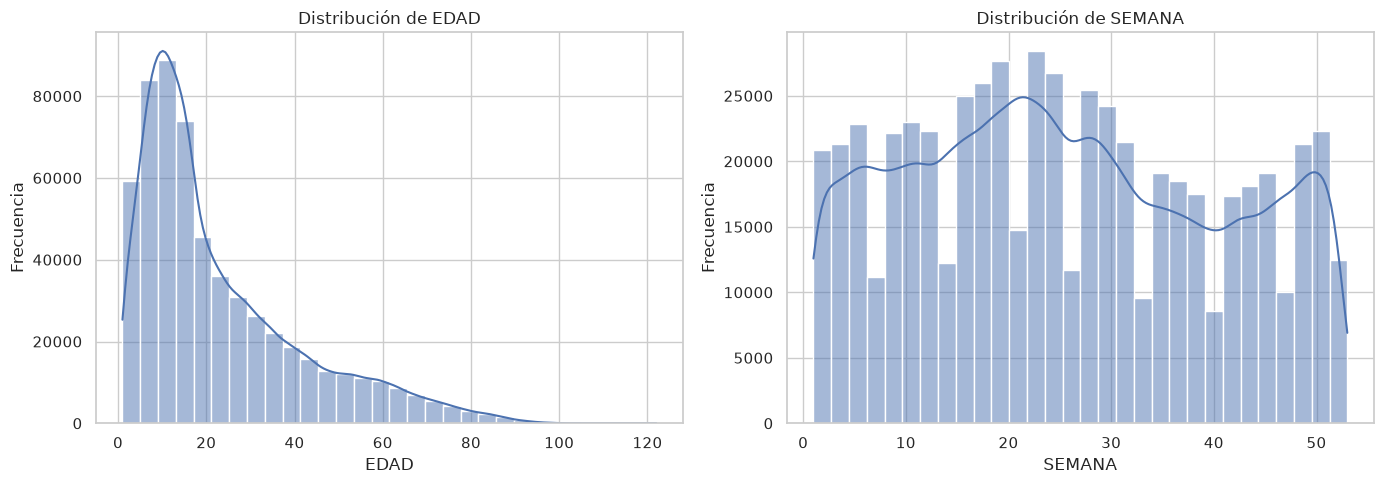

In [45]:
columnas_numericas = ["EDAD", "SEMANA"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, columna in zip(axes, columnas_numericas):
    sns.histplot(data=df, x=columna, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

No se incluyeron todos los campos numéricos porque algunas columnas, como COD_DPTO_O y COD_MUN_O, representan códigos de identificación y no cantidades numéricas que tenga sentido distribuir mediante histogramas. Para cumplir completamente el objetivo del análisis exploratorio, se deben evaluar las demás variables numéricas y seleccionar aquellas cuya distribución aporte información relevante.
### Insight:
La variable de edad revela una marcada hiperconcentración de casos en la población infantil, situando su punto más crítico entre los 5 y 12 años, lo que exige dirigir la asignación presupuestal y las campañas preventivas directamente hacia el entorno escolar e instituciones pediátricas. En cuanto a la estacionalidad, el comportamiento bimodal muestra dos picos previsibles de alta demanda: el principal entre las semanas 20 y 25 (mayo-junio) superando los 25,000 casos semanales, y un repunte secundario entre las semanas 48 y 52 (noviembre-diciembre). En consecuencia, la gestión operativa debe programar la compra de insumos y la rotación de personal asistencial antes de la semana 18 para evitar la saturación del servicio durante las ventanas de mayor afluencia.

### 2. Boxplot de la edad

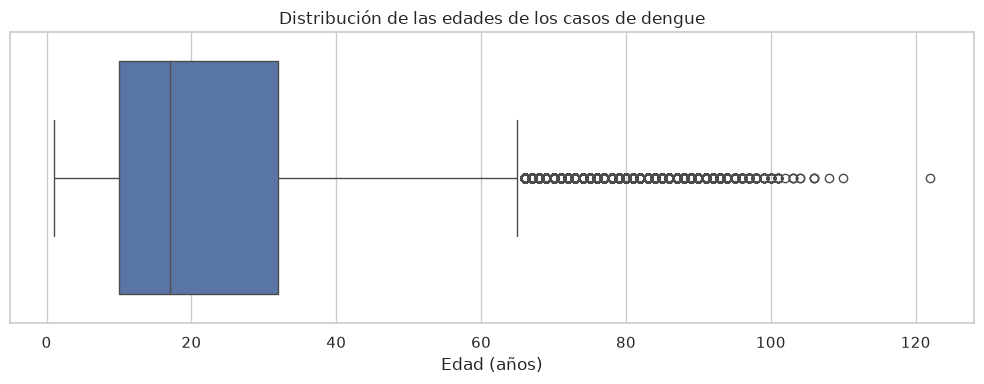

Cantidad de edades válidas: 581071
Edad mínima: 1
Edad máxima: 122


In [36]:
col_edad = "EDAD"


if col_edad is not None:
    edades = pd.to_numeric(df[col_edad], errors="coerce").dropna()

    plt.figure(figsize=(10, 4))
    sns.boxplot(x=edades)
    plt.title("Distribución de las edades de los casos de dengue")
    plt.xlabel("Edad (años)")
    plt.tight_layout()
    plt.show()

    print("Cantidad de edades válidas:", len(edades))
    print("Edad mínima:", edades.min())
    print("Edad máxima:", edades.max())
else:
    print("No se detectó automáticamente la columna de edad.")
    print("Revisa las columnas impresas en la primera celda.")

La gran mayoría de las columnas restantes (SEXO, TIP_SS, Departamento_ocurrencia, PAC_HOS) representan categorías, etiquetas o valores binarios. Aplicar un boxplot a estas variables generaría líneas planas o bloques rígidos sin cuartiles ni variabilidad interpretable.
### Insight:
La distribución de edades evidencia una alta concentración de casos de dengue en la población infantojuvenil, situando la mediana en aproximadamente 17 años y comprimiendo el 50% central de los registros entre los 10 y 32 años. La dispersión superior clasifica a los adultos mayores de 65 años como valores atípicos (*outliers*), detectando incluso valores extremos superiores a los 100 y 120 años que sugieren posibles errores de digitación en el sistema. En consecuencia, las intervenciones de salud pública deben priorizar los entornos escolares y juveniles, complementándose con una auditoría de calidad de datos para validar las edades extremas reportadas.

### 3. Heatmap de correlación de Pearson y Spearman

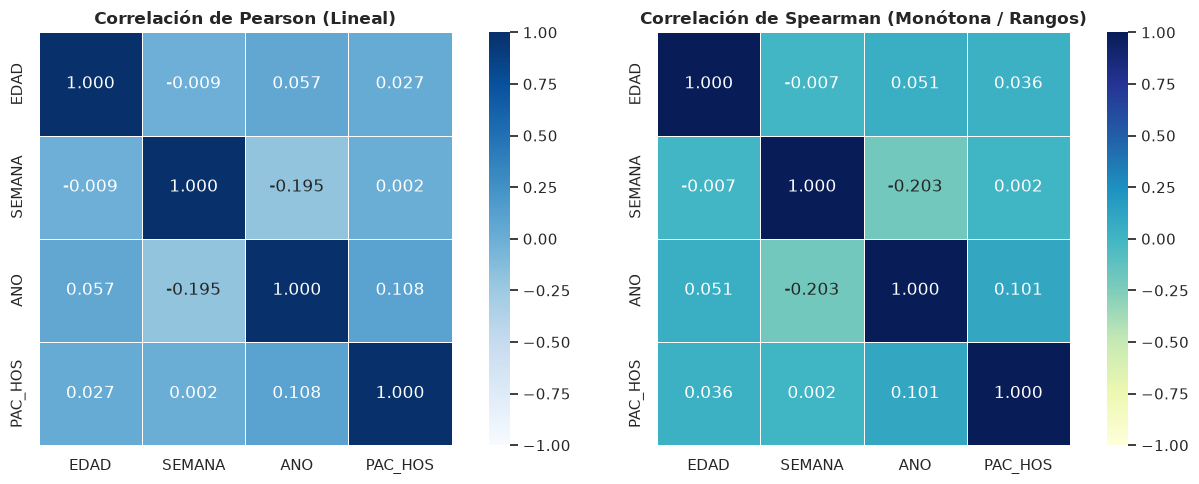

In [49]:


# 1. Selección de variables cuantitativas/métricas numéricas reales
vars_correlacion = ["EDAD", "SEMANA", "ANO", "PAC_HOS"]

# 2. Cálculo de matrices de correlación
matriz_pearson = df[vars_correlacion].corr(method="pearson")
matriz_spearman = df[vars_correlacion].corr(method="spearman")

# 3. Visualización gráfica comparativa con Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Pearson
sns.heatmap(
    matriz_pearson,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    ax=axes[0],
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=0.5,
)
axes[0].set_title(
    "Correlación de Pearson (Lineal)", fontsize=12, fontweight="bold"
)

# Heatmap Spearman
sns.heatmap(
    matriz_spearman,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    ax=axes[1],
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=0.5,
)
axes[1].set_title(
    "Correlación de Spearman (Monótona / Rangos)",
    fontsize=12,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

### Insight:
Las matrices de correlación de Pearson y Spearman revelan coeficientes cercanos a cero ($\vert{}r\vert{} < 0.10$) entre la edad, la semana epidemiológica y la hospitalización del paciente, lo que confirma la independencia matemática entre la severidad del evento, la edad de contagio y la época del año. Esto significa que ni la estacionalidad ni la edad del afectado condicionan la probabilidad de desarrollar cuadros graves que requieran manejo hospitalario. Por lo tanto, los protocolos de triaje, la asignación de camas de mayor complejidad y la gestión de recursos asistenciales deben aplicarse de forma continua y estandarizada en toda la red de atención, sin asunciones de menor riesgo para rangos etarios o periodos específicos.

### 4. Evolución semanal por año

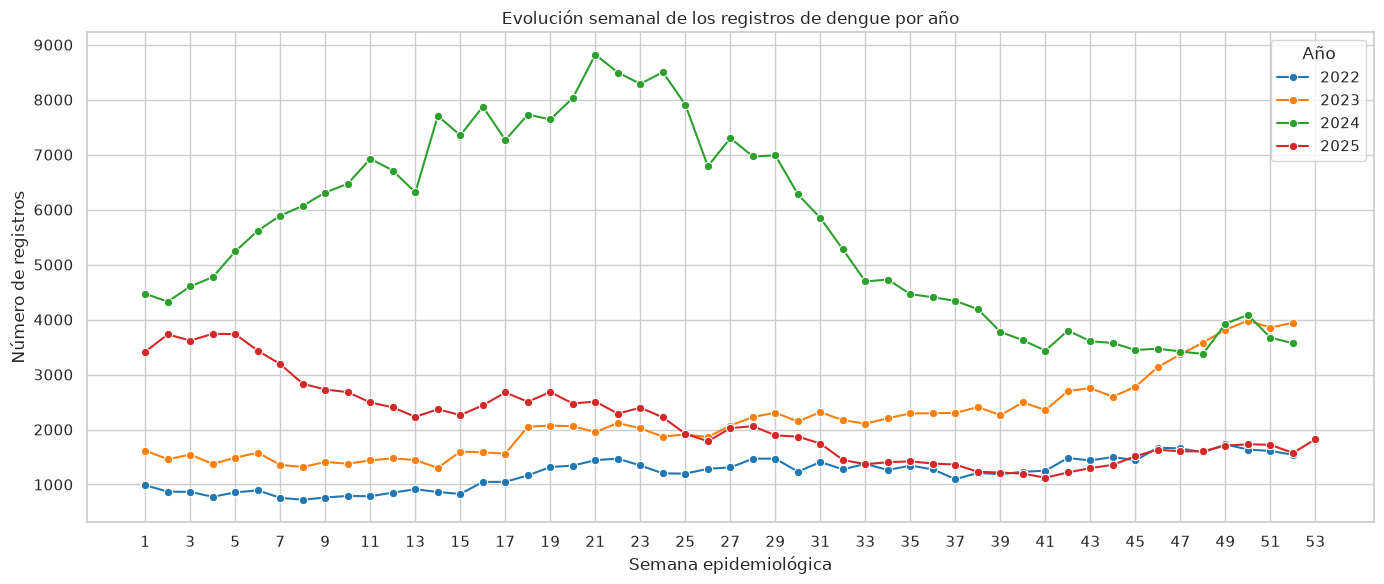

In [42]:
evolucion = df.groupby(["ANO", "SEMANA"]).size().reset_index(name="CASOS")

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=evolucion,
    x="SEMANA",
    y="CASOS",
    hue="ANO",
    palette="tab10",
    marker="o"
)

plt.title("Evolución semanal de los registros de dengue por año")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Número de registros")
plt.xticks(range(1, 54, 2))
plt.legend(title="Año")
plt.tight_layout()
plt.show()

### Insight:
La evolución interanual evidencia que el riesgo epidemiológico varía drásticamente entre periodos, destacando el año 2024 como un brote epidémico atípico que alcanzó un pico crítico cercano a los 8,800 casos semanales entre las semanas 15 y 25, en fuerte contraste con la curva endémica baja de 2022 y la estabilización progresiva vista en 2025. Este comportamiento demuestra cómo la tendencia ascendente iniciada a finales de 2023 detonó una sobrecarga de atención en el primer semestre del año siguiente, confirmando que la asignación de presupuestos y reservas de insumos no debe basarse en promedios históricos estáticos, sino en sistemas de alerta temprana activados desde el último trimestre del año previo.

### 5.Top 10 departamentos con más registros

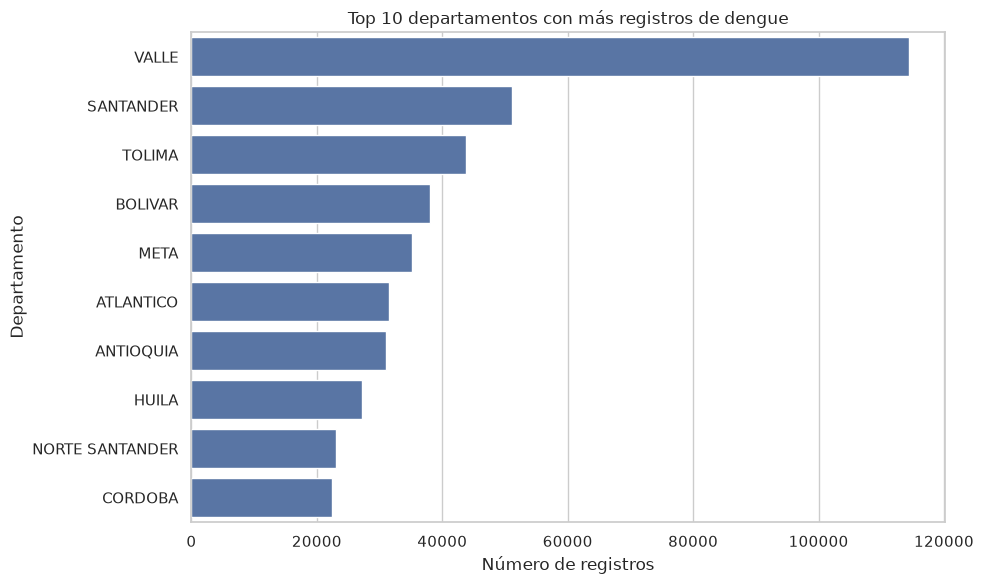

In [39]:
top10 = df["Departamento_ocurrencia"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index)

plt.title("Top 10 departamentos con más registros de dengue")
plt.xlabel("Número de registros")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

### Insight:
La distribución geográfica evidencia una extrema concentración territorial de la carga epidemiológica, encabezada de forma abrumadora por el departamento del Valle con cerca de 115,000 registros, superando por más del doble al segundo y tercer lugar (Santander y Tolima). Este comportamiento demuestra que la demanda asistencial no se distribuye homogéneamente en el territorio nacional, sino que responde a focos endémicos regionales altamente críticos que absorben la mayor parte del impacto poblacional. En consecuencia, la asignación de presupuestos, la logística de insumos médicos y las campañas de control del vector deben focalizarse con prioridad estratégica en estas regiones de alta densidad para maximizar la efectividad de la respuesta en salud pública.

###  6. Proporción de Hospitalización (PAC_HOS) por Grupo Etario

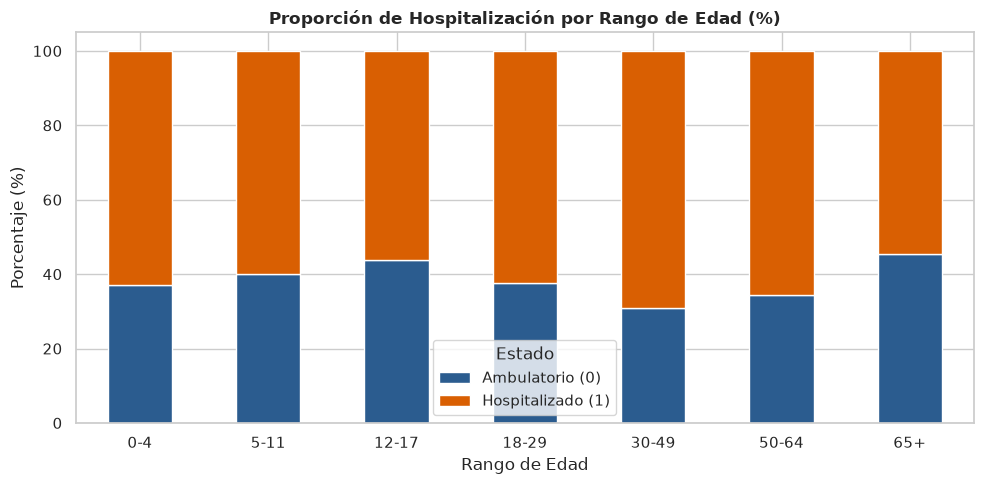

In [50]:
import numpy as np
import seaborn as sns

# Crear grupos de edad
bins = [0, 5, 12, 18, 30, 50, 65, 120]
labels = ["0-4", "5-11", "12-17", "18-29", "30-49", "50-64", "65+"]
df["rango_edad"] = pd.cut(df["EDAD"], bins=bins, labels=labels, right=False)

# Tabla cruzada en porcentaje
hosp_edad = (
    pd.crosstab(df["rango_edad"], df["PAC_HOS"], normalize="index") * 100
)

# Gráfico de barras apiladas
hosp_edad.plot(
    kind="bar", stacked=True, figsize=(10, 5), color=["#2b5c8f", "#d95f02"]
)
plt.title(
    "Proporción de Hospitalización por Rango de Edad (%)", fontweight="bold"
)
plt.xlabel("Rango de Edad")
plt.ylabel("Porcentaje (%)")
plt.legend(["Ambulatorio (0)", "Hospitalizado (1)"], title="Estado")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insight:
La proporción de hospitalización supera holgadamente el 50% en todos los rangos etarios, alcanzando su punto máximo en los adultos de 30 a 49 años (cerca del 70% de requerimiento de ingreso) y manteniéndose entre el 55% y 65% en el resto de los grupos. Este hallazgo evidencia que la necesidad de atención intrahospitalaria por dengue es transversal a toda la población y no se limita exclusivamente a los extremos de edad (niños o adultos mayores). En consecuencia, la planificación de capacidad instalada, camas de observación y personal asistencial debe prepararse para una alta demanda de hospitalización en todos los ciclos de vida, sin restringir los recursos críticos a unidades pediátricas o geriátricas.